In [3]:
%pip install pandas matplotlib scipy

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.9 MB 5.4 MB/s eta 0:00:02
   ------- -------------------------------- 2.1/10.9 MB 4.8 MB/s eta 0:00:02
   ------------ --------------------------- 3.4/10.9 MB 5.4 MB/s eta 0:00:02
   --------------- ------------------------ 4.2/10.9 MB 4.9 MB/s eta 0:00:02
   ----------------- ---------------------- 4.7/10.9 MB 4.4 MB/s eta 0:00:02
   ------------------- -------------------- 5.2/10.9 MB 4.0 MB/s eta 0:00:02
   -------------------- ------------------- 5.5/10.9 MB 3.7 MB/s eta 0:00:02
   --------------------- ------------------ 5.8/10.9 MB 3.4 MB/s eta 0:00:02
   ---------------------- ----------------- 6.0/10.9 MB 3.3 MB/s eta 0:00:02
   ------------------------ --------------- 6.6/10.9 MB 3.0 MB/s eta 0:00:02
   -------------------------- ------------- 7.1/10.9 MB 3.0 MB/s eta 0:00:02
   --------------------------- ------------ 7.6/10.9 MB 2.9 MB/s eta 0:00:02
   ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


['bfs_nummer', 'bezirksnummer', 'kantonsnummer', 'name', 'Foglio3_Somma di Pernottamenti', 'type_count']
Coefficiente: 18407.408090096174
Intercetta: -93.89688431474497
R²: 0.4466534051787515
P-value: 3.330292289570029e-06


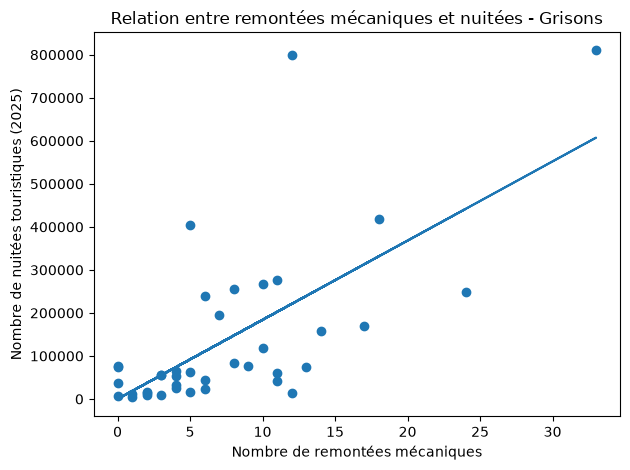

In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Caricare i dati
df = pd.read_csv(r"C:\Users\anfor\OneDrive - Université de Lausanne\TERZO ANNO\geoinformatique II\progetto\analyse_intersection.csv")

# Controllare i nomi delle colonne
print(df.columns.tolist())

# Selezionare le variabili
df = df[["type_count", "Foglio3_Somma di Pernottamenti"]].copy()

# Convertire in numerico
df["type_count"] = pd.to_numeric(df["type_count"], errors="coerce")
df["Foglio3_Somma di Pernottamenti"] = pd.to_numeric(df["Foglio3_Somma di Pernottamenti"], errors="coerce")

# Eliminare solo i dati mancanti
df = df.dropna()

# Regressione lineare
result = linregress(df["type_count"], df["Foglio3_Somma di Pernottamenti"])

print("Coefficiente:", result.slope)
print("Intercetta:", result.intercept)
print("R²:", result.rvalue**2)
print("P-value:", result.pvalue)

# Grafico
plt.scatter(df["type_count"], df["Foglio3_Somma di Pernottamenti"])

x = df["type_count"]
y = result.intercept + result.slope * x

plt.plot(x, y)
plt.xlabel("Nombre de remontées mécaniques")
plt.ylabel("Nombre de nuitées touristiques (2025)")
plt.title("Relation entre remontées mécaniques et nuitées - Grisons")
plt.tight_layout()
plt.show()


In [6]:
%pip install pandas matplotlib scipy statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 9.4 MB/s eta 0:00:02
   ------- -------------------------------- 2.1/11.3 MB 6.2 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/11.3 MB 6.8 MB/s eta 0:00:02
   ------------------ --------------------- 5.2/11.3 MB 6.7 MB/s eta 0:00:01
   ------------------------ --------------- 6.8/11.3 MB 6.7 MB/s eta 0:00:01
   ---------------------------- ----------- 8.1/11.3 MB 6.6 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 6.6 MB/s eta 0:00:01
   -------------------------------------- - 11.0/11.3 MB 6.6 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 6.5 MB/s  0:00:01

   ---------------------------------------- 0/7 [wrapt]
   ---------------------------------------- 0/7 [wrapt]
   ----------- ---------------------------- 2/7 [patsy]
   ----------- ---------------------------- 2/7 [patsy]
   ----------


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

import pandas as pd
import numpy as np
import statsmodels.api as sm

# 1. CARICAMENTO DEL CSV

df = pd.read_csv(
    r"C:\Users\anfor\OneDrive - Université de Lausanne\TERZO ANNO\geoinformatique II\progetto\intersection_regression_multiple.csv",
    encoding="utf-8-sig"
)

# Visualizzare i nomi delle colonne
print(df.columns.tolist())


# 2. DEFINIZIONE DELLE VARIABILI

id_col = "bfs_nummer"

y_col = "Foglio3_Somma di Pernottamenti"

x_cols = [
    "type_count",
    "rArretSuperieur_count"
]


# 3. CONVERSIONE IN VALORI NUMERICI

for col in [y_col] + x_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# 4. CONTROLLO DEI DATI

print("Numero di righe:", len(df))
print("Comuni unici:", df[id_col].nunique())

if df[id_col].duplicated().any():
    raise ValueError(
        "ATTENZIONE: ci sono comuni duplicati!"
    )

data = df.dropna(
    subset=[id_col, y_col] + x_cols
).copy()

print("Comuni utilizzati:", len(data))


# 5. REGRESSIONE LINEARE MULTIPLA

Y = data[y_col]
X = data[x_cols]

X = sm.add_constant(X)

model = sm.OLS(Y, X).fit()

print("\nRISULTATI DELLA REGRESSIONE:")
print(model.summary())


# 6. CALCOLO DEI VALORI PREDIETTI

data["NUITEES_PREDITES"] = model.predict(X)


# 7. CALCOLO DEI RESIDUI

data["RESIDUS"] = (
    data[y_col] - data["NUITEES_PREDITES"]
)


# 8. INTERPRETAZIONE DEI RESIDUI

def interpretation(residu):
    if residu > 0:
        return "Plus de nuitées que prévu"
    elif residu < 0:
        return "Moins de nuitées que prévu"
    else:
        return "Valeur égale à la valeur prévue"

data["INTERPRETATION"] = data["RESIDUS"].apply(
    interpretation
)


# 9. ESPORTAZIONE DEI RISULTATI

colonnes_resultats = [
    id_col,
    y_col,
    "type_count",
    "rArretSuperieur_count",
    "NUITEES_PREDITES",
    "RESIDUS",
    "INTERPRETATION"
]

resultats = data[colonnes_resultats]

resultats.to_csv(r"C:\Users\anfor\OneDrive - Université de Lausanne\TERZO ANNO\geoinformatique II\progetto\resultats_regression.csv"
    ,
    index=False,
    encoding="utf-8-sig"
)

print("\nRegressione completata!")
print("File esportato: resultats_regression.csv")


['fid', 'id', 'bfs_nummer', 'name', 'Foglio3_Somma di Pernottamenti', 'type_count', 'rArretSuperieur_count']
Numero di righe: 100
Comuni unici: 100
Comuni utilizzati: 39

RISULTATI DELLA REGRESSIONE:
                                  OLS Regression Results                                  
Dep. Variable:     Foglio3_Somma di Pernottamenti   R-squared:                       0.464
Model:                                        OLS   Adj. R-squared:                  0.435
Method:                             Least Squares   F-statistic:                     15.61
Date:                            Tue, 03 Nov 2026   Prob (F-statistic):           1.31e-05
Time:                                    15:41:05   Log-Likelihood:                -516.86
No. Observations:                              39   AIC:                             1040.
Df Residuals:                                  36   BIC:                             1045.
Df Model:                                       2                       

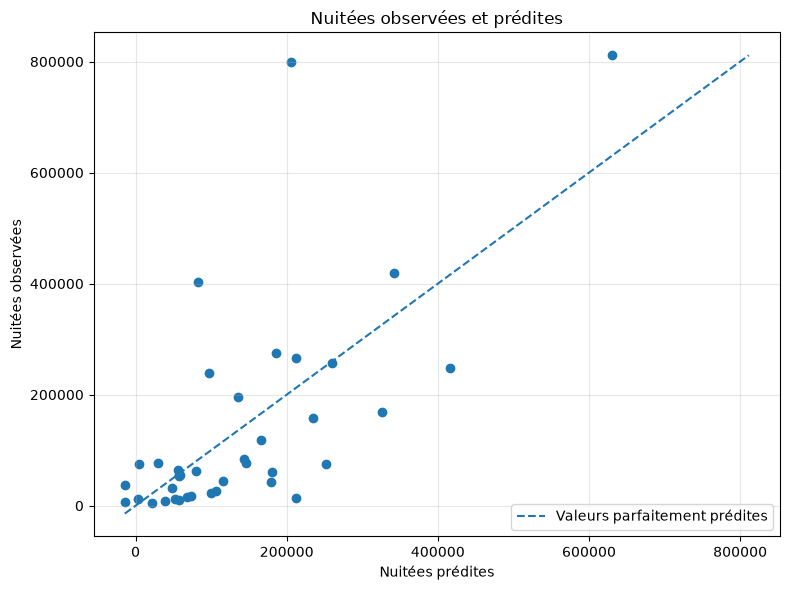

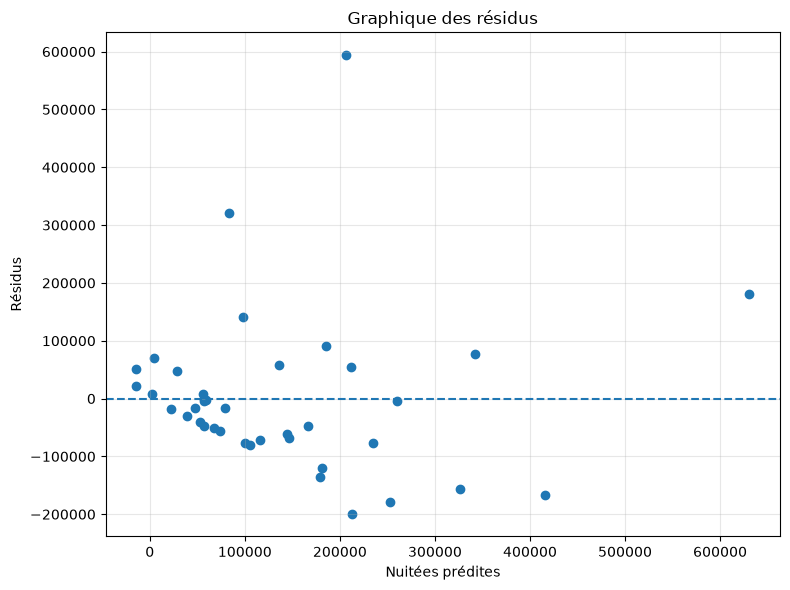

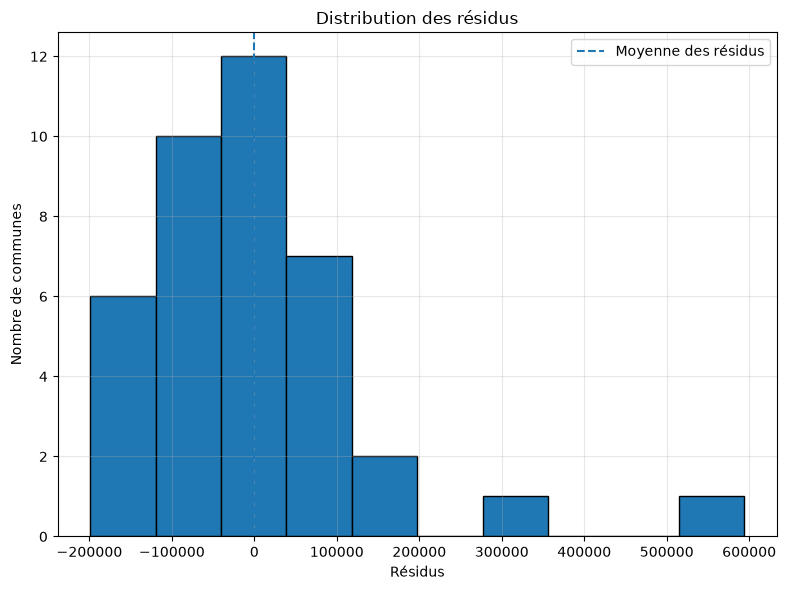

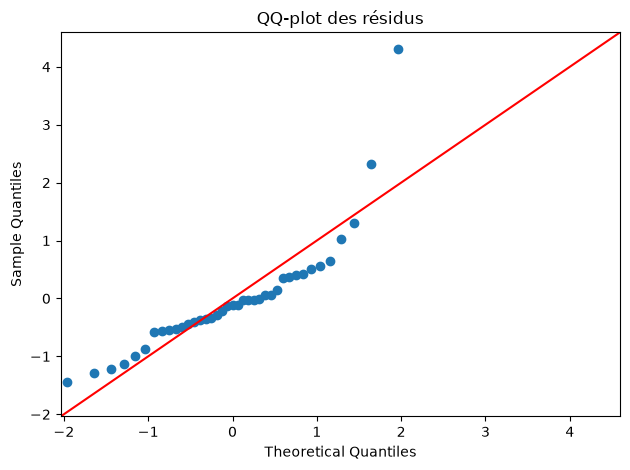

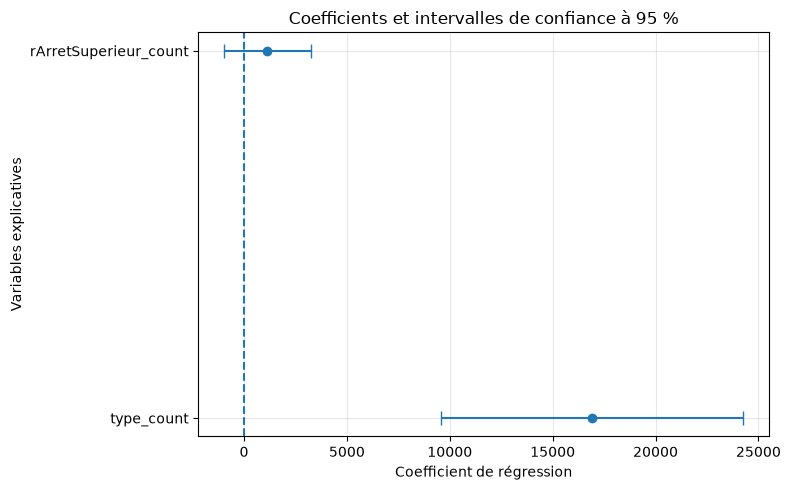


TEST DE SHAPIRO-WILK
Statistique: 0.8086574016552994
P-value: 1.2738802783154626e-05


In [9]:

import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

# --------------------------------------------------
# GRAFICO 1: VALORI OSSERVATI VS PREDDETTI
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(data["NUITEES_PREDITES"], data[y_col])

limite_min = min(data["NUITEES_PREDITES"].min(), data[y_col].min())
limite_max = max(data["NUITEES_PREDITES"].max(), data[y_col].max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--",
    label="Valeurs parfaitement prédites"
)

plt.xlabel("Nuitées prédites")
plt.ylabel("Nuitées observées")
plt.title("Nuitées observées et prédites")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# GRAFICO 2: RESIDUI
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(data["NUITEES_PREDITES"], data["RESIDUS"])
plt.axhline(y=0, linestyle="--")

plt.xlabel("Nuitées prédites")
plt.ylabel("Résidus")
plt.title("Graphique des résidus")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# GRAFICO 3: DISTRIBUZIONE DEI RESIDUI
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.hist(data["RESIDUS"], bins=10, edgecolor="black")

plt.axvline(
    data["RESIDUS"].mean(),
    linestyle="--",
    label="Moyenne des résidus"
)

plt.xlabel("Résidus")
plt.ylabel("Nombre de communes")
plt.title("Distribution des résidus")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# GRAFICO 4: QQ-PLOT
# --------------------------------------------------

sm.qqplot(model.resid, line="45", fit=True)

plt.title("QQ-plot des résidus")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# GRAFICO 5: COEFFICIENTI DELLA REGRESSIONE
# --------------------------------------------------

coefficients = model.params.drop("const")
intervals = model.conf_int().loc[coefficients.index]

plt.figure(figsize=(8, 5))

plt.errorbar(
    coefficients.values,
    coefficients.index,
    xerr=[
        coefficients.values - intervals[0].values,
        intervals[1].values - coefficients.values
    ],
    fmt="o",
    capsize=5
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Coefficient de régression")
plt.ylabel("Variables explicatives")
plt.title("Coefficients et intervalles de confiance à 95 %")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# TEST DE NORMALITE DES RESIDUI
# --------------------------------------------------

shapiro = stats.shapiro(model.resid)

print("\nTEST DE SHAPIRO-WILK")
print("Statistique:", shapiro.statistic)
print("P-value:", shapiro.pvalue)


                                  OLS Regression Results                                  
Dep. Variable:     Foglio3_Somma di Pernottamenti   R-squared:                       0.140
Model:                                        OLS   Adj. R-squared:                  0.117
Method:                             Least Squares   F-statistic:                     6.017
Date:                            Tue, 03 Nov 2026   Prob (F-statistic):             0.0190
Time:                                    19:32:26   Log-Likelihood:                -526.10
No. Observations:                              39   AIC:                             1056.
Df Residuals:                                  37   BIC:                             1060.
Df Model:                                       1                                         
Covariance Type:                        nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]


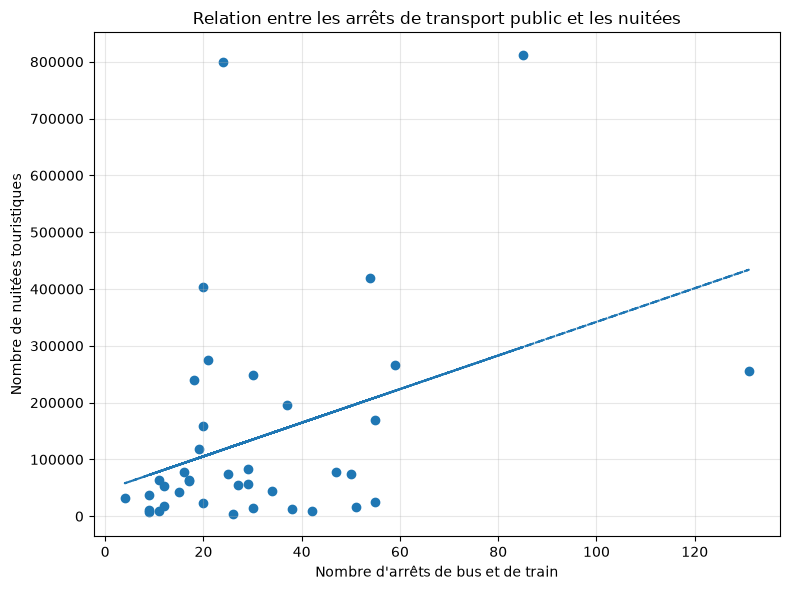

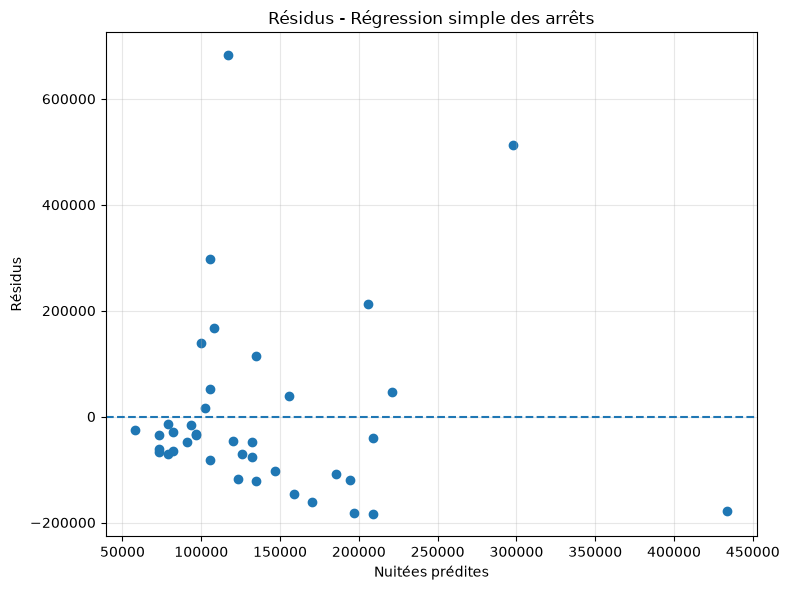

In [11]:

import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Caricamento dati
df = pd.read_csv(
    r"C:\Users\anfor\OneDrive - Université de Lausanne\TERZO ANNO\geoinformatique II\progetto\resultats_regression.csv",
    encoding="utf-8-sig"
)

# Variabili
Y_col = "Foglio3_Somma di Pernottamenti"
X_col = "rArretSuperieur_count"

# Conversione numerica
df[Y_col] = pd.to_numeric(df[Y_col], errors="coerce")
df[X_col] = pd.to_numeric(df[X_col], errors="coerce")

# Selezione dati
data = df.dropna(subset=[Y_col, X_col]).copy()

Y = data[Y_col]
X = sm.add_constant(data[[X_col]])

# Regressione lineare semplice
model_arrets = sm.OLS(Y, X).fit()

print(model_arrets.summary())

# Valori predetti
data["NUITEES_PREDITES"] = model_arrets.predict(X)

# Residui
data["RESIDUS"] = Y - data["NUITEES_PREDITES"]

# Grafico: fermate e pernottamenti
plt.figure(figsize=(8, 6))

plt.scatter(data[X_col], data[Y_col])

plt.plot(
    data[X_col],
    data["NUITEES_PREDITES"],
    linestyle="--"
)

plt.xlabel("Nombre d'arrêts de bus et de train")
plt.ylabel("Nombre de nuitées touristiques")
plt.title("Relation entre les arrêts de transport public et les nuitées")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Grafico dei residui
plt.figure(figsize=(8, 6))

plt.scatter(
    data["NUITEES_PREDITES"],
    data["RESIDUS"]
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Nuitées prédites")
plt.ylabel("Résidus")
plt.title("Résidus - Régression simple des arrêts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
